### OOP 2: Datenkapselung - Übungen

Im ersten Notebook waren alle Attribute **öffentlich**: Jeder konnte sie von außen lesen und ändern.
Hier lernst du, wie eine Klasse ihre Daten **schützt** (Datenkapselung) und den Zugriff über **Zugriffsmethoden** regelt.

Dieses Notebook ist das zweite der OOP-Reihe:

1. Klassen und Objekte
2. **Datenkapselung** (dieses Notebook)
3. Beziehungen zwischen Klassen (Assoziation)
4. Vererbung
5. Spezielle Methoden und Dataclasses (nach dem Notebook über Typangaben)

Die Abschnitte über Klassenattribute, Klassenmethoden und den Lebenszyklus von Objekten sind für das **Leistungsfach** gedacht.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Manche Beispiele enden absichtlich mit einer Fehlermeldung. Danach folgen viele kleine Übungen.
Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

## 1. Private Attribute

#### Das Problem mit öffentlichen Attributen

Ist der Kontostand ein öffentliches Attribut, kann jeder Teil des Programms ihn beliebig ändern, auch auf unsinnige Werte.
Die Methode `abheben()` prüft zwar, ob genug Geld da ist, aber man kann sie einfach umgehen.

In [ ]:
class Konto:
    def __init__(self, inhaber):
        self.inhaber = inhaber
        self.kontostand = 0

    def abheben(self, betrag):
        if betrag <= self.kontostand:
            self.kontostand -= betrag

k = Konto('Ali')
k.abheben(500)
print(k.kontostand)
k.kontostand = -1000000
print(k.kontostand)

#### Datenkapselung und Geheimnisprinzip

**Datenkapselung** heißt: Die Attribute eines Objekts sind von außen nicht zugänglich (**privat**). Man kommt nur über die
**Methoden** der Klasse an sie heran. Die Klasse entscheidet also selbst, was mit ihren Daten passieren darf.
Wie die Klasse ihre Daten intern speichert, bleibt ihr Geheimnis (**Geheimnisprinzip**).

In Python macht man ein Attribut privat, indem man seinen Namen mit **zwei Unterstrichen** beginnt: `self.__kontostand`.
Innerhalb der Klasse benutzt man es ganz normal, von außen gibt `k.__kontostand` einen `AttributeError`.

Im Klassendiagramm steht vor privaten Attributen ein `-`, vor öffentlichen ein `+`.

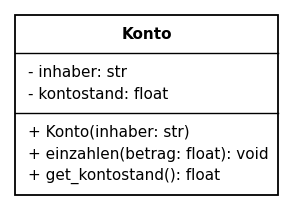



In [ ]:
class Konto:
    def __init__(self, inhaber):
        self.__inhaber = inhaber
        self.__kontostand = 0

    def einzahlen(self, betrag):
        if betrag > 0:
            self.__kontostand += betrag

    def get_kontostand(self):
        return self.__kontostand

k = Konto('Ali')
k.einzahlen(50)
print(k.get_kontostand())
print(k.__kontostand)

#### Achtung: Zuweisen von außen gibt keinen Fehler

`k.__kontostand = 5` von außen gibt **keinen** Fehler. Python legt dann aber ein **neues**, öffentliches Attribut an, das mit dem
privaten Attribut nichts zu tun hat. Das private Attribut bleibt unverändert.

Python versteckt private Attribute nur, indem es ihren Namen intern ändert (aus `__kontostand` wird `_Konto__kontostand`).
Wer es darauf anlegt, kommt also doch heran. Datenkapselung ist in Python eine **Abmachung**: Von außen benutzt man nur die Methoden.

In [ ]:
class Konto:
    def __init__(self):
        self.__kontostand = 100

    def get_kontostand(self):
        return self.__kontostand

k = Konto()
k.__kontostand = 5
print(k.__kontostand)
print(k.get_kontostand())

#### Aufgabe 1.1

Mache in der Klasse `Tresor` das Attribut `code` privat (`__code`). Ergänze eine Methode `oeffnen(versuch)`, die `True` zurückgibt,
wenn der Versuch mit dem Code übereinstimmt, sonst `False`. Teste mit `'1234'` und `'4711'`.

**Erwartete Ausgabe:**
```
False
True
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Tresor:
    def __init__(self, code):
        self.__code = code

    def oeffnen(self, versuch):
        return versuch == self.__code

t = Tresor('4711')
print(t.oeffnen('1234'))
print(t.oeffnen('4711'))
```

</details>

#### Aufgabe 1.2

Setze die Klasse aus dem Diagramm um. Der Zähler beginnt bei 0. Zähle 3-mal und gib den Stand mit `get_stand()` aus.

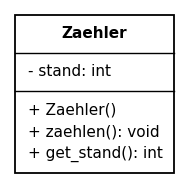



**Erwartete Ausgabe:**
```
3
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Zaehler:
    def __init__(self):
        self.__stand = 0

    def zaehlen(self):
        self.__stand += 1

    def get_stand(self):
        return self.__stand

z = Zaehler()
for i in range(3):
    z.zaehlen()
print(z.get_stand())
```

</details>

#### Aufgabe 1.3

Versuche, von außen das private Attribut `__stand` zu lesen. Fange den `AttributeError` ab und gib dann `privat!` aus.

**Erwartete Ausgabe:**
```
privat!
```

In [ ]:
class Zaehler:
    def __init__(self):
        self.__stand = 7

z = Zaehler()
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Zaehler:
    def __init__(self):
        self.__stand = 7

z = Zaehler()
try:
    print(z.__stand)
except AttributeError:
    print('privat!')
```

</details>

#### Aufgabe 1.4

Setze die Klasse um. `einzahlen()` und `abheben()` akzeptieren nur positive Beträge, `abheben()` außerdem nur, wenn genug Geld da ist;
sonst passiert nichts. Führe aus: einzahlen 100, abheben 30, abheben 500, einzahlen -20. Gib danach den Kontostand aus.

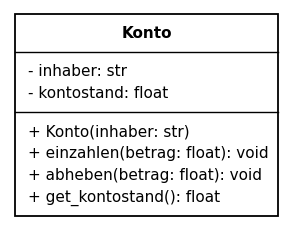



**Erwartete Ausgabe:**
```
70
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Konto:
    def __init__(self, inhaber):
        self.__inhaber = inhaber
        self.__kontostand = 0

    def einzahlen(self, betrag):
        if betrag > 0:
            self.__kontostand += betrag

    def abheben(self, betrag):
        if 0 < betrag <= self.__kontostand:
            self.__kontostand -= betrag

    def get_kontostand(self):
        return self.__kontostand

k = Konto('Bea')
k.einzahlen(100)
k.abheben(30)
k.abheben(500)
k.einzahlen(-20)
print(k.get_kontostand())
```

</details>

#### Aufgabe 1.5

Ergänze die Klasse `Spieler` um `__str__` in der Form `Mia: 3 Leben`. `__str__` darf die privaten Attribute benutzen, weil sie in
der Klasse steht. Lass den Spieler zweimal getroffen werden und gib ihn aus.

**Erwartete Ausgabe:**
```
Mia: 3 Leben
```

In [ ]:
class Spieler:
    def __init__(self, name):
        self.__name = name
        self.__leben = 5

    def getroffen(self):
        if self.__leben > 0:
            self.__leben -= 1
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Spieler:
    def __init__(self, name):
        self.__name = name
        self.__leben = 5

    def getroffen(self):
        if self.__leben > 0:
            self.__leben -= 1

    def __str__(self):
        return f'{self.__name}: {self.__leben} Leben'

s = Spieler('Mia')
s.getroffen()
s.getroffen()
print(s)
```

</details>

#### Aufgabe 1.6

Ändere von außen `k.__stand = 99` und gib danach `k.__stand` und `k.get_stand()` aus.

**Erwartete Ausgabe:**
```
99
10
```

In [ ]:
class Kasse:
    def __init__(self):
        self.__stand = 10

    def get_stand(self):
        return self.__stand

k = Kasse()
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Kasse:
    def __init__(self):
        self.__stand = 10

    def get_stand(self):
        return self.__stand

k = Kasse()
k.__stand = 99
print(k.__stand)
print(k.get_stand())
```

</details>

#### Aufgabe 1.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Box:
    def __init__(self):
        self.__geheim = 1
        self.offen = 2

    def summe(self):
        return self.__geheim + self.offen

b = Box()
b.offen = 10
print(b.summe())
print(b.offen)

#### Aufgabe 1.8

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Box:
    def __init__(self):
        self.__geheim = 1

b = Box()
print(b.__geheim)

#### Aufgabe 1.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Box:
    def __init__(self):
        self.__wert = 3

    def wert(self):
        return self.__wert

b = Box()
b.__wert = 8
print(b.wert(), b.__wert)

## 2. Zugriffsmethoden: get und set

#### Getter und Setter

Damit man private Attribute trotzdem lesen und ändern kann, schreibt man **Zugriffsmethoden**:

- Ein **Getter** `get_name()` gibt den Wert zurück.
- Ein **Setter** `set_name(wert)` setzt einen neuen Wert. Der Setter kann dabei **prüfen**, ob der Wert sinnvoll ist,
  und ihn sonst ablehnen, z. B. mit `raise ValueError(...)`.

Nicht jedes Attribut braucht beides: Gibt es nur einen Getter, kann man den Wert von außen lesen, aber nicht ändern.

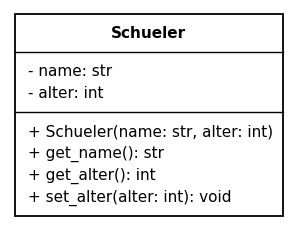



In [ ]:
class Schueler:
    def __init__(self, name, alter):
        self.__name = name
        self.set_alter(alter)

    def get_name(self):
        return self.__name

    def get_alter(self):
        return self.__alter

    def set_alter(self, alter):
        if alter < 0 or alter > 120:
            raise ValueError('ungültiges Alter')
        self.__alter = alter

s = Schueler('Ali', 15)
s.set_alter(16)
print(s.get_name(), s.get_alter())
try:
    s.set_alter(-3)
except ValueError as e:
    print('Fehler:', e)
print(s.get_alter())

#### Der Konstruktor benutzt den Setter

Im Beispiel darüber ruft der Konstruktor `self.set_alter(alter)` auf. So wird die Prüfung **nicht doppelt** geschrieben, und auch
`Schueler('Bea', 200)` gibt einen Fehler.

In [ ]:
class Schueler:
    def __init__(self, name, alter):
        self.__name = name
        self.set_alter(alter)

    def set_alter(self, alter):
        if alter < 0 or alter > 120:
            raise ValueError('ungültiges Alter')
        self.__alter = alter

try:
    s = Schueler('Bea', 200)
except ValueError as e:
    print('Fehler:', e)

#### Aufgabe 2.1

Setze die Klasse um. `set_titel()` akzeptiert nur Titel, die nicht leer sind, sonst löst sie `ValueError('leerer Titel')` aus.
Erzeuge ein Buch, ändere den Titel auf `Momo` und gib Titel und Autor aus. Versuche dann, einen leeren Titel zu setzen, fange den Fehler ab
und gib die Meldung aus.

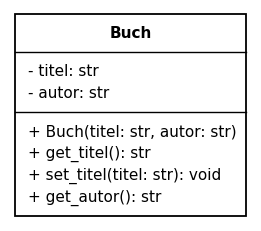



**Erwartete Ausgabe:**
```
Momo Michael Ende
leerer Titel
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Buch:
    def __init__(self, titel, autor):
        self.set_titel(titel)
        self.__autor = autor

    def get_titel(self):
        return self.__titel

    def set_titel(self, titel):
        if titel == '':
            raise ValueError('leerer Titel')
        self.__titel = titel

    def get_autor(self):
        return self.__autor

b = Buch('Mono', 'Michael Ende')
b.set_titel('Momo')
print(b.get_titel(), b.get_autor())
try:
    b.set_titel('')
except ValueError as e:
    print(e)
```

</details>

#### Aufgabe 2.2

Setze die Klasse um. Eine Temperatur unter −273.15 °C gibt es nicht: `set_celsius()` löst dann `ValueError('unter dem absoluten Nullpunkt')` aus.
`get_fahrenheit()` gibt `celsius * 9 / 5 + 32` zurück. Gib für 20 °C und 100 °C den Fahrenheit-Wert aus und versuche dann −300 °C zu setzen.

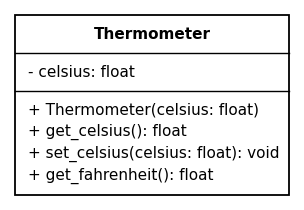



**Erwartete Ausgabe:**
```
68.0
212.0
unter dem absoluten Nullpunkt
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Thermometer:
    def __init__(self, celsius):
        self.set_celsius(celsius)

    def get_celsius(self):
        return self.__celsius

    def set_celsius(self, celsius):
        if celsius < -273.15:
            raise ValueError('unter dem absoluten Nullpunkt')
        self.__celsius = celsius

    def get_fahrenheit(self):
        return self.__celsius * 9 / 5 + 32

th = Thermometer(20)
print(th.get_fahrenheit())
th.set_celsius(100)
print(th.get_fahrenheit())
try:
    th.set_celsius(-300)
except ValueError as e:
    print(e)
```

</details>

#### Aufgabe 2.3

Ergänze die Klasse `Note` um `get_wert()` und `set_wert(wert)`. Gültig sind nur ganze Zahlen von 1 bis 6, sonst `ValueError`.
Setze nacheinander die Werte in `versuche` und gib nach jedem Versuch den aktuellen Wert oder `abgelehnt: 7` aus.

**Erwartete Ausgabe:**
```
2
abgelehnt: 7
1
abgelehnt: 0
```

In [ ]:
versuche = [2, 7, 1, 0]

class Note:
    def __init__(self, fach, wert):
        self.__fach = fach
        self.set_wert(wert)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
versuche = [2, 7, 1, 0]

class Note:
    def __init__(self, fach, wert):
        self.__fach = fach
        self.set_wert(wert)

    def get_wert(self):
        return self.__wert

    def set_wert(self, wert):
        if wert < 1 or wert > 6:
            raise ValueError('ungültige Note')
        self.__wert = wert

n = Note('Mathe', 3)
for v in versuche:
    try:
        n.set_wert(v)
        print(n.get_wert())
    except ValueError:
        print('abgelehnt:', v)
```

</details>

#### Aufgabe 2.4

Die Klasse `Artikel` hat einen Getter, aber keinen Setter für den Preis. Stattdessen gibt es eine Methode `rabatt(prozent)`.
Ergänze `get_preis()` und `rabatt()` (nur 0 bis 50 % erlaubt, sonst `ValueError`) und gib den Preis nach 20 % Rabatt mit zwei Nachkommastellen aus.
Versuche danach 80 % Rabatt.

**Erwartete Ausgabe:**
```
71.92
Rabatt nicht erlaubt
```

In [ ]:
class Artikel:
    def __init__(self, name, preis):
        self.__name = name
        self.__preis = preis
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Artikel:
    def __init__(self, name, preis):
        self.__name = name
        self.__preis = preis

    def get_preis(self):
        return self.__preis

    def rabatt(self, prozent):
        if prozent < 0 or prozent > 50:
            raise ValueError('Rabatt nicht erlaubt')
        self.__preis = self.__preis * (100 - prozent) / 100

a = Artikel('Jacke', 89.90)
a.rabatt(20)
print(f'{a.get_preis():.2f}')
try:
    a.rabatt(80)
except ValueError as e:
    print(e)
```

</details>

#### Aufgabe 2.5

Setze die Klasse um. Der Setter `set_benutzername()` erlaubt nur Namen aus 3 bis 12 Zeichen ohne Leerzeichen, sonst `ValueError`.
`set_passwort()` verlangt mindestens 8 Zeichen. Ein Getter für das Passwort fehlt mit Absicht. `pruefe(pw)` gibt zurück, ob ein Passwort stimmt.
Teste: Benutzer `mia_07` mit Passwort `sommer2026`, prüfe `sommer` und `sommer2026`, versuche den Namen `mia 07` zu setzen.

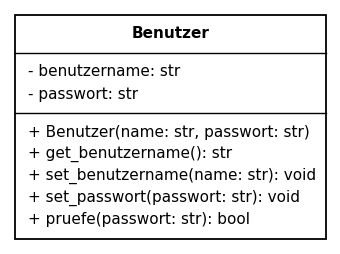



**Erwartete Ausgabe:**
```
False
True
ungültiger Benutzername
mia_07
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Benutzer:
    def __init__(self, name, passwort):
        self.set_benutzername(name)
        self.set_passwort(passwort)

    def get_benutzername(self):
        return self.__benutzername

    def set_benutzername(self, name):
        if len(name) < 3 or len(name) > 12 or ' ' in name:
            raise ValueError('ungültiger Benutzername')
        self.__benutzername = name

    def set_passwort(self, passwort):
        if len(passwort) < 8:
            raise ValueError('Passwort zu kurz')
        self.__passwort = passwort

    def pruefe(self, passwort):
        return passwort == self.__passwort

b = Benutzer('mia_07', 'sommer2026')
print(b.pruefe('sommer'))
print(b.pruefe('sommer2026'))
try:
    b.set_benutzername('mia 07')
except ValueError as e:
    print(e)
print(b.get_benutzername())
```

</details>

#### Aufgabe 2.6

Ergänze die Klasse `Rechteck` um Getter und Setter für Breite und Höhe (nur positive Werte, sonst `ValueError`) und `get_flaeche()`.
Die Fläche wird **nicht** gespeichert, sondern immer neu berechnet. Gib die Fläche aus, setze die Breite auf 10 und gib sie wieder aus.

**Erwartete Ausgabe:**
```
12
30
```

In [ ]:
class Rechteck:
    def __init__(self, breite, hoehe):
        self.set_breite(breite)
        self.set_hoehe(hoehe)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Rechteck:
    def __init__(self, breite, hoehe):
        self.set_breite(breite)
        self.set_hoehe(hoehe)

    def get_breite(self):
        return self.__breite

    def set_breite(self, breite):
        if breite <= 0:
            raise ValueError('Breite muss positiv sein')
        self.__breite = breite

    def get_hoehe(self):
        return self.__hoehe

    def set_hoehe(self, hoehe):
        if hoehe <= 0:
            raise ValueError('Höhe muss positiv sein')
        self.__hoehe = hoehe

    def get_flaeche(self):
        return self.__breite * self.__hoehe

r = Rechteck(4, 3)
print(r.get_flaeche())
r.set_breite(10)
print(r.get_flaeche())
```

</details>

#### Aufgabe 2.7

Ergänze die Klasse `Uhr` um `set_zeit(stunde, minute)` mit Prüfung (0–23, 0–59, sonst `ValueError`), `get_zeit()` (Text `hh:mm`) und
`minute_weiter()`, die die Uhr um eine Minute vorstellt (nach 23:59 kommt 00:00). Stelle 23:58 ein und stelle dreimal weiter, jeweils mit Ausgabe.

**Erwartete Ausgabe:**
```
23:59
00:00
00:01
```

In [ ]:
class Uhr:
    def __init__(self):
        self.__stunde = 0
        self.__minute = 0
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Uhr:
    def __init__(self):
        self.__stunde = 0
        self.__minute = 0

    def set_zeit(self, stunde, minute):
        if stunde < 0 or stunde > 23 or minute < 0 or minute > 59:
            raise ValueError('ungültige Zeit')
        self.__stunde = stunde
        self.__minute = minute

    def get_zeit(self):
        return f'{self.__stunde:02d}:{self.__minute:02d}'

    def minute_weiter(self):
        self.__minute += 1
        if self.__minute == 60:
            self.__minute = 0
            self.__stunde = (self.__stunde + 1) % 24

u = Uhr()
u.set_zeit(23, 58)
for i in range(3):
    u.minute_weiter()
    print(u.get_zeit())
```

</details>

#### Aufgabe 2.8

Ein Getter, der eine **Liste** zurückgibt, gibt einen Verweis auf die private Liste heraus: Wer sie von außen ändert, ändert das Objekt.
Zeige das: Hole mit `get_noten()` die Liste, hänge `6` an und gib danach `get_noten()` aus. Ändere den Getter dann so, dass er eine Kopie
(`list(self.__noten)`) zurückgibt, und wiederhole den Versuch mit einem neuen Objekt der geänderten Klasse `Zeugnis2`.

**Erwartete Ausgabe:**
```
[2, 1, 3, 6]
[2, 1, 3]
```

In [ ]:
class Zeugnis:
    def __init__(self):
        self.__noten = [2, 1, 3]

    def get_noten(self):
        return self.__noten
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Zeugnis:
    def __init__(self):
        self.__noten = [2, 1, 3]

    def get_noten(self):
        return self.__noten
z = Zeugnis()
noten = z.get_noten()
noten.append(6)
print(z.get_noten())

class Zeugnis2:
    def __init__(self):
        self.__noten = [2, 1, 3]

    def get_noten(self):
        return list(self.__noten)

z2 = Zeugnis2()
noten = z2.get_noten()
noten.append(6)
print(z2.get_noten())
```

</details>

#### Aufgabe 2.9

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Note:
    def __init__(self, wert):
        self.set_wert(wert)

    def set_wert(self, wert):
        if 1 <= wert <= 6:
            self.__wert = wert

    def get_wert(self):
        return self.__wert

n = Note(2)
n.set_wert(9)
n.set_wert(4)
n.set_wert(0)
print(n.get_wert())

#### Aufgabe 2.10

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Note:
    def __init__(self, wert):
        self.set_wert(wert)

    def set_wert(self, wert):
        if 1 <= wert <= 6:
            self.__wert = wert

    def get_wert(self):
        return self.__wert

n = Note(9)
print(n.get_wert())

## 3. Private Methoden und geschützte Attribute

#### Private Methoden

Auch Methoden können privat sein: `def __pruefe(self, ...)`. Sie sind **Hilfsmethoden**, die nur innerhalb der Klasse gebraucht werden.
Von außen kann man sie nicht aufrufen. Im Diagramm stehen sie mit `-`.

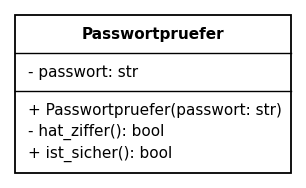



In [ ]:
class Passwortpruefer:
    def __init__(self, passwort):
        self.__passwort = passwort

    def __hat_ziffer(self):
        for z in self.__passwort:
            if z.isdigit():
                return True
        return False

    def ist_sicher(self):
        return len(self.__passwort) >= 8 and self.__hat_ziffer()

print(Passwortpruefer('geheim42!').ist_sicher())
print(Passwortpruefer('geheimnis').ist_sicher())

#### Geschützte Attribute

Beginnt ein Name mit **einem** Unterstrich (`self._punkte`), ist das Attribut **geschützt** (*protected*). Python verhindert den Zugriff
von außen dabei gar nicht. Der Unterstrich ist eine Abmachung: „Nur für diese Klasse und ihre Unterklassen gedacht.“
Was Unterklassen sind, lernst du im Notebook über Vererbung; dort ist der Unterschied zu privaten Attributen wichtig.

Im Klassendiagramm steht vor geschützten Attributen ein `#`.

In [ ]:
class Figur:
    def __init__(self, name):
        self._name = name
        self.__geheim = 42

f = Figur('Ritter')
print(f._name)
print(hasattr(f, '_name'), hasattr(f, '__geheim'))

#### `hasattr()`

`hasattr(objekt, 'name')` prüft, ob ein Objekt ein Attribut (oder eine Methode) mit diesem Namen hat, und gibt `True` oder `False` zurück.

In [ ]:
class Punkt:
    def __init__(self):
        self.x = 1

p = Punkt()
print(hasattr(p, 'x'), hasattr(p, 'y'))

#### Aufgabe 3.1

Setze die Klasse um. Die private Methode `__ist_gueltig(datum)` prüft, ob ein Text die Form `TT.MM.` hat (Länge 6, Punkte an Position 2 und 5).
`hinzufuegen()` fügt einen Termin nur hinzu, wenn das Datum gültig ist, und gibt zurück, ob es geklappt hat. `anzahl()` gibt die Zahl der Termine zurück.
Teste mit `'24.12.'`, `'1.1.'` und `'31.10.'` und gib danach die Anzahl aus.

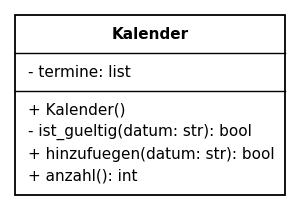



**Erwartete Ausgabe:**
```
True
False
True
2
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Kalender:
    def __init__(self):
        self.__termine = []

    def __ist_gueltig(self, datum):
        return len(datum) == 6 and datum[2] == '.' and datum[5] == '.'

    def hinzufuegen(self, datum):
        if not self.__ist_gueltig(datum):
            return False
        self.__termine.append(datum)
        return True

    def anzahl(self):
        return len(self.__termine)

k = Kalender()
for d in ['24.12.', '1.1.', '31.10.']:
    print(k.hinzufuegen(d))
print(k.anzahl())
```

</details>

#### Aufgabe 3.2

Ergänze die Klasse `Bruch` um eine private Methode `__kuerzen()`, die Zähler und Nenner durch ihren ggT (`math.gcd`) teilt. Der Konstruktor ruft
sie auf, sodass jeder Bruch gekürzt gespeichert wird. Gib `Bruch(6, 8)` und `Bruch(10, 5)` aus.

**Erwartete Ausgabe:**
```
3/4
2/1
```

In [ ]:
import math

class Bruch:
    def __init__(self, zaehler, nenner):
        self.__zaehler = zaehler
        self.__nenner = nenner
        self.__kuerzen()

    def __str__(self):
        return f'{self.__zaehler}/{self.__nenner}'
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import math

class Bruch:
    def __init__(self, zaehler, nenner):
        self.__zaehler = zaehler
        self.__nenner = nenner
        self.__kuerzen()

    def __str__(self):
        return f'{self.__zaehler}/{self.__nenner}'

    def __kuerzen(self):
        g = math.gcd(self.__zaehler, self.__nenner)
        self.__zaehler //= g
        self.__nenner //= g

print(Bruch(6, 8))
print(Bruch(10, 5))
```

</details>

#### Aufgabe 3.3

Versuche, die private Methode `__kuerzen()` eines Bruchs von außen aufzurufen. Fange den Fehler ab und gib den Namen des Fehlertyps aus.

**Erwartete Ausgabe:**
```
AttributeError
```

In [ ]:
class Bruch:
    def __init__(self, z, n):
        self.__z = z
        self.__n = n

    def __kuerzen(self):
        pass

b = Bruch(2, 4)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Bruch:
    def __init__(self, z, n):
        self.__z = z
        self.__n = n

    def __kuerzen(self):
        pass

b = Bruch(2, 4)
try:
    b.__kuerzen()
except Exception as e:
    print(type(e).__name__)
```

</details>

#### Aufgabe 3.4

Gib mit `hasattr()` für jeden Namen in `namen` aus, ob das Objekt `f` ein Attribut mit diesem Namen hat, in der Form `_name True`.

**Erwartete Ausgabe:**
```
_name True
__leben False
staerke True
leben False
```

In [ ]:
class Figur:
    def __init__(self):
        self._name = 'Ritter'
        self.__leben = 3
        self.staerke = 7

f = Figur()
namen = ['_name', '__leben', 'staerke', 'leben']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Figur:
    def __init__(self):
        self._name = 'Ritter'
        self.__leben = 3
        self.staerke = 7

f = Figur()
namen = ['_name', '__leben', 'staerke', 'leben']
for n in namen:
    print(n, hasattr(f, n))
```

</details>

#### Aufgabe 3.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Box:
    def __init__(self):
        self._a = 1
        self.__b = 2

    def __doppelt(self, x):
        return 2 * x

    def rechne(self):
        return self.__doppelt(self._a + self.__b)

b = Box()
b._a = 5
print(b.rechne())

## 4. Klassenattribute (Leistungsfach)

#### Attribute, die zur Klasse gehören

Ein **Klassenattribut** steht direkt in der Klasse (nicht in `__init__` und ohne `self`). Es gibt es nur **einmal** für die ganze Klasse,
alle Objekte teilen es sich. Man spricht es über den Klassennamen an: `Schueler.anzahl`.

Typische Anwendungen: ein Zähler für alle erzeugten Objekte, oder Werte, die für alle gleich sind (z. B. ein Zinssatz).

Die bisherigen Attribute mit `self.` heißen **Objektattribute**: Jedes Objekt hat seine eigenen.
Im Klassendiagramm werden Klassenattribute **unterstrichen**.

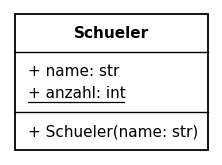



In [ ]:
class Schueler:
    anzahl = 0

    def __init__(self, name):
        self.name = name
        Schueler.anzahl += 1

a = Schueler('Ali')
b = Schueler('Bea')
print(Schueler.anzahl)
print(a.name, b.name)

#### Achtung bei `self.klassenattribut = ...`

Lesen kann man ein Klassenattribut auch über ein Objekt: `a.anzahl`. Aber **Zuweisen** über ein Objekt (`a.anzahl = 10`) legt ein neues
**Objektattribut** an, das das Klassenattribut nur für dieses Objekt verdeckt. Deshalb ändert man Klassenattribute immer über den Klassennamen.

Auch private Klassenattribute gibt es: `__anzahl = 0`, innerhalb der Klasse dann `Schueler.__anzahl`.

In [ ]:
class Konto:
    zinssatz = 2

k1 = Konto()
k2 = Konto()
print(k1.zinssatz, k2.zinssatz)
Konto.zinssatz = 3
print(k1.zinssatz, k2.zinssatz)
k1.zinssatz = 10
print(k1.zinssatz, k2.zinssatz, Konto.zinssatz)

#### Aufgabe 4.1

Setze die Klasse um. Das Klassenattribut `anzahl` zählt, wie viele Autos erzeugt wurden. Erzeuge drei Autos und gib `Auto.anzahl` aus.

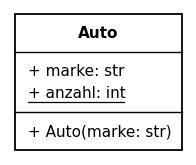



**Erwartete Ausgabe:**
```
3
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Auto:
    anzahl = 0

    def __init__(self, marke):
        self.marke = marke
        Auto.anzahl += 1

a = Auto('VW')
b = Auto('Opel')
c = Auto('BMW')
print(Auto.anzahl)
```

</details>

#### Aufgabe 4.2

Gib jedem neuen Ticket eine fortlaufende Nummer: Das Klassenattribut `naechste_nr` beginnt bei 1; der Konstruktor gibt dem Ticket die aktuelle Nummer
als Objektattribut `nr` und erhöht dann `naechste_nr`. Erzeuge Tickets für alle Namen in `namen` und gib jeweils `Nr. 1: Ali` aus.

**Erwartete Ausgabe:**
```
Nr. 1: Ali
Nr. 2: Bea
Nr. 3: Cem
Nr. 4: Dana
```

In [ ]:
namen = ['Ali', 'Bea', 'Cem', 'Dana']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
namen = ['Ali', 'Bea', 'Cem', 'Dana']
class Ticket:
    naechste_nr = 1

    def __init__(self, name):
        self.name = name
        self.nr = Ticket.naechste_nr
        Ticket.naechste_nr += 1

for n in namen:
    tk = Ticket(n)
    print(f'Nr. {tk.nr}: {tk.name}')
```

</details>

#### Aufgabe 4.3

Alle Sparkonten haben denselben Zinssatz, ein Klassenattribut `zinssatz = 2` (Prozent). Die Methode `zinsen()` gibt die Zinsen für ein Jahr zurück.
Gib die Zinsen für zwei Konten mit 500 und 1200 Euro aus, ändere den Zinssatz für alle auf 3 und gib die Zinsen erneut aus.

**Erwartete Ausgabe:**
```
10.0 24.0
15.0 36.0
```

In [ ]:
class Sparkonto:
    zinssatz = 2

    def __init__(self, stand):
        self.stand = stand
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Sparkonto:
    zinssatz = 2

    def __init__(self, stand):
        self.stand = stand

    def zinsen(self):
        return self.stand * Sparkonto.zinssatz / 100

a = Sparkonto(500)
b = Sparkonto(1200)
print(a.zinsen(), b.zinsen())
Sparkonto.zinssatz = 3
print(a.zinsen(), b.zinsen())
```

</details>

#### Aufgabe 4.4

Ein Klassenattribut kann auch eine Liste sein, die sich alle Objekte teilen. Jedes neue `Mitglied` trägt seinen Namen in die Liste `Mitglied.alle` ein.
Erzeuge drei Mitglieder und gib die Liste aus.

**Erwartete Ausgabe:**
```
['Ali', 'Bea', 'Cem']
```

In [ ]:
class Mitglied:
    alle = []

    def __init__(self, name):
        self.name = name
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Mitglied:
    alle = []

    def __init__(self, name):
        self.name = name
        Mitglied.alle.append(name)

Mitglied('Ali')
Mitglied('Bea')
Mitglied('Cem')
print(Mitglied.alle)
```

</details>

#### Aufgabe 4.5

Die Klasse `Wuerfel` hat das Klassenattribut `SEITEN = 6` (eine Konstante, deshalb in Großbuchstaben). Ändere es auf 20 und würfle mit `random.seed(4)`
zehnmal, Ergebnisse als Liste.

**Erwartete Ausgabe:**
```
[8, 10, 4, 13, 16, 5, 3, 3, 1, 13]
```

In [ ]:
import random
random.seed(4)

class Wuerfel:
    SEITEN = 6

    def werfen(self):
        return random.randint(1, Wuerfel.SEITEN)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import random
random.seed(4)

class Wuerfel:
    SEITEN = 6

    def werfen(self):
        return random.randint(1, Wuerfel.SEITEN)
Wuerfel.SEITEN = 20
w = Wuerfel()
wuerfe = []
for i in range(10):
    wuerfe.append(w.werfen())
print(wuerfe)
```

</details>

#### Aufgabe 4.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Box:
    zahl = 1

    def __init__(self):
        Box.zahl += 1

a = Box()
b = Box()
print(Box.zahl, a.zahl, b.zahl)

#### Aufgabe 4.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Box:
    zahl = 1

a = Box()
b = Box()
a.zahl = 5
Box.zahl = 7
print(a.zahl, b.zahl)

## 5. Klassenmethoden und statische Methoden (Leistungsfach)

#### Klassenmethoden

Eine **Klassenmethode** gehört zur Klasse, nicht zu einem Objekt. Man schreibt `@classmethod` darüber. Ihr erster Parameter heißt `cls`:
Das ist die **Klasse** selbst (nicht ein Objekt). Aufgerufen wird sie über den Klassennamen: `Schueler.get_anzahl()`.

Typische Anwendungen:
- Getter für private Klassenattribute.
- Ein **zweiter Weg, Objekte zu erzeugen**, z. B. aus einem Text: `Schueler.aus_text('Ali;16')`. `cls(...)` ruft dabei den Konstruktor auf.

Zeilen mit `@` vor einer Methode heißen **Dekoratoren**. Sie verändern, wie die Methode aufgerufen wird. Im Diagramm sind Klassenmethoden unterstrichen.

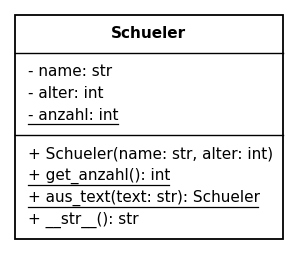



In [ ]:
class Schueler:
    __anzahl = 0

    def __init__(self, name, alter):
        self.__name = name
        self.__alter = alter
        Schueler.__anzahl += 1

    @classmethod
    def get_anzahl(cls):
        return cls.__anzahl

    @classmethod
    def aus_text(cls, text):
        name, alter = text.split(';')
        return cls(name, int(alter))

    def __str__(self):
        return f'{self.__name} ({self.__alter})'

a = Schueler('Ali', 16)
b = Schueler.aus_text('Bea;15')
print(b)
print(Schueler.get_anzahl())

#### Statische Methoden

Eine **statische Methode** (`@staticmethod`) hat weder `self` noch `cls`. Sie ist eine gewöhnliche Funktion, die nur aus Gründen der Ordnung
in der Klasse steht, weil sie inhaltlich dazugehört, z. B. eine Prüfung oder eine Umrechnung.

In [ ]:
class Temperatur:
    @staticmethod
    def c_nach_f(celsius):
        return celsius * 9 / 5 + 32

    @staticmethod
    def ist_gueltig(celsius):
        return celsius >= -273.15

print(Temperatur.c_nach_f(25))
print(Temperatur.ist_gueltig(-300))

#### Aufgabe 5.1

Setze die Klasse um. `get_anzahl()` ist eine Klassenmethode, die das private Klassenattribut zurückgibt. Erzeuge zwei Lampen und gib die Anzahl aus.

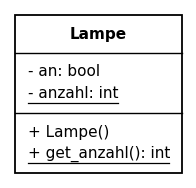



**Erwartete Ausgabe:**
```
2
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Lampe:
    __anzahl = 0

    def __init__(self):
        self.__an = False
        Lampe.__anzahl += 1

    @classmethod
    def get_anzahl(cls):
        return cls.__anzahl

a = Lampe()
b = Lampe()
print(Lampe.get_anzahl())
```

</details>

#### Aufgabe 5.2

Ergänze die Klasse `Punkt` um eine Klassenmethode `aus_text(text)`, die einen Punkt aus einem Text wie `'(3|4)'` erzeugt
(Klammern mit `strip('()')` entfernen, an `|` zerlegen). Erzeuge alle Punkte aus `texte` und gib sie aus.

**Erwartete Ausgabe:**
```
P(3|4)
P(-1|0)
P(10|2)
```

In [ ]:
texte = ['(3|4)', '(-1|0)', '(10|2)']

class Punkt:
    def __init__(self, x, y):
        self.__x = x
        self.__y = y

    def __str__(self):
        return f'P({self.__x}|{self.__y})'
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
texte = ['(3|4)', '(-1|0)', '(10|2)']

class Punkt:
    def __init__(self, x, y):
        self.__x = x
        self.__y = y

    def __str__(self):
        return f'P({self.__x}|{self.__y})'

    @classmethod
    def aus_text(cls, text):
        x, y = text.strip('()').split('|')
        return cls(int(x), int(y))

for t in texte:
    print(Punkt.aus_text(t))
```

</details>

#### Aufgabe 5.3

Ergänze die Klasse `Datum` um eine statische Methode `ist_schaltjahr(jahr)` (durch 4 teilbar, aber nicht durch 100, außer durch 400)
und eine statische Methode `tage_im_monat(monat, jahr)`, die `ist_schaltjahr` für den Februar benutzt. Gib für die Paare in `tests` die Tage aus.

**Erwartete Ausgabe:**
```
2 2024 29
2 1900 28
2 2000 29
4 2026 30
```

In [ ]:
tests = [(2, 2024), (2, 1900), (2, 2000), (4, 2026)]

class Datum:
    TAGE = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
tests = [(2, 2024), (2, 1900), (2, 2000), (4, 2026)]

class Datum:
    TAGE = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

    @staticmethod
    def ist_schaltjahr(jahr):
        return (jahr % 4 == 0 and jahr % 100 != 0) or jahr % 400 == 0

    @staticmethod
    def tage_im_monat(monat, jahr):
        if monat == 2 and Datum.ist_schaltjahr(jahr):
            return 29
        return Datum.TAGE[monat - 1]

for monat, jahr in tests:
    print(monat, jahr, Datum.tage_im_monat(monat, jahr))
```

</details>

#### Aufgabe 5.4

Setze die Klasse um. `ist_gueltige_iban(text)` ist statisch: Eine (vereinfachte) IBAN ist gültig, wenn sie mit `DE` beginnt und danach genau
20 Ziffern folgen. Der Konstruktor löst `ValueError('ungültige IBAN')` aus, wenn die IBAN nicht gültig ist. Teste mit allen Texten in `tests`.

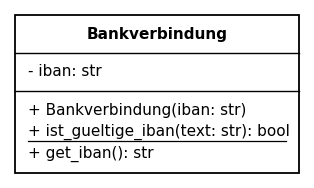



**Erwartete Ausgabe:**
```
DE12345678901234567890
ungültige IBAN
ungültige IBAN
ungültige IBAN
```

In [ ]:
tests = ['DE12345678901234567890', 'DE1234', 'AT12345678901234567890', 'DE1234567890123456789X']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
tests = ['DE12345678901234567890', 'DE1234', 'AT12345678901234567890', 'DE1234567890123456789X']
class Bankverbindung:
    def __init__(self, iban):
        if not Bankverbindung.ist_gueltige_iban(iban):
            raise ValueError('ungültige IBAN')
        self.__iban = iban

    @staticmethod
    def ist_gueltige_iban(text):
        return len(text) == 22 and text[:2] == 'DE' and text[2:].isdigit()

    def get_iban(self):
        return self.__iban

for iban in tests:
    try:
        print(Bankverbindung(iban).get_iban())
    except ValueError as e:
        print(e)
```

</details>

#### Aufgabe 5.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Zahl:
    __erzeugt = 0

    def __init__(self, wert):
        self.wert = wert
        Zahl.__erzeugt += 1

    @classmethod
    def null(cls):
        return cls(0)

    @classmethod
    def erzeugt(cls):
        return cls.__erzeugt

    @staticmethod
    def summe(a, b):
        return a + b

a = Zahl(3)
b = Zahl.null()
print(b.wert, Zahl.erzeugt())
print(Zahl.summe(a.wert, 4), Zahl.erzeugt())

## 6. Der Lebenszyklus eines Objekts (Leistungsfach)

#### Erzeugen, benutzen, zerstören

Jedes Objekt durchläuft drei Phasen:

1. **Erzeugen** (Instanziierung): Python legt das Objekt im Speicher an und ruft den Konstruktor `__init__` auf.
2. **Benutzen**: Über Variablen (Referenzen) greift man auf Attribute und Methoden zu.
3. **Zerstören**: Verweist **keine** Variable mehr auf das Objekt, kann es niemand mehr benutzen. Python gibt dann den Speicher frei
   (*Garbage Collection*, „Müllabfuhr“).

Eine Methode `__del__(self)` wird aufgerufen, kurz bevor das Objekt zerstört wird. `del variable` löscht eine **Variable**, nicht das Objekt:
Zerstört wird das Objekt erst, wenn kein Verweis mehr übrig ist.

In [ ]:
class Ballon:
    def __init__(self, farbe):
        self.farbe = farbe
        print(farbe, 'wird aufgeblasen')

    def __del__(self):
        print(self.farbe, 'platzt')

a = Ballon('rot')
b = a
del a
print('a gelöscht')
del b
print('b gelöscht')
c = Ballon('blau')
c = Ballon('grün')
print('Ende')

#### Aufgabe 6.1

Schreibe eine Klasse `Gast` mit einem Klassenattribut `anwesend = 0`. Der Konstruktor erhöht es, `__del__` verringert es wieder. Erzeuge drei Gäste
`a`, `b`, `c`, gib `Gast.anwesend` aus, lösche `b` mit `del` und gib die Zahl wieder aus.

**Erwartete Ausgabe:**
```
3
2
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Gast:
    anwesend = 0

    def __init__(self, name):
        self.name = name
        Gast.anwesend += 1

    def __del__(self):
        Gast.anwesend -= 1

a = Gast('Ali')
b = Gast('Bea')
c = Gast('Cem')
print(Gast.anwesend)
del b
print(Gast.anwesend)
```

</details>

#### Aufgabe 6.2

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Box:
    def __init__(self, n):
        self.n = n
        print('neu', n)

    def __del__(self):
        print('weg', self.n)

x = Box(1)
y = x
x = Box(2)
print('Mitte')
y = None
print('Ende')

## 7. Ausblick: Properties

#### `@property`

In Python schreibt man statt `get_x()`/`set_x()` oft **Properties**. Von außen sieht es aus, als greife man direkt auf ein Attribut zu
(`k.kontostand`), tatsächlich wird aber eine Methode aufgerufen. Der Getter bekommt `@property`, der Setter `@name.setter`.

Im Unterricht verwenden wir die Zugriffsmethoden `get_...` und `set_...`. Properties solltest du aber erkennen, wenn sie dir begegnen.

In [ ]:
class Schueler:
    def __init__(self, alter):
        self.alter = alter          # ruft schon den Setter auf

    @property
    def alter(self):
        return self.__alter

    @alter.setter
    def alter(self, wert):
        if wert < 0:
            raise ValueError('ungültiges Alter')
        self.__alter = wert

s = Schueler(15)
s.alter = 16
print(s.alter)
try:
    s.alter = -1
except ValueError as e:
    print(e)

#### Aufgabe 7.1

Schreibe die Klasse `Quadrat` mit einer Property `seite` (Getter und Setter, nur positive Werte) und einer Property `flaeche` **nur mit Getter**.
Setze die Seite auf 5 und gib die Fläche aus. Versuche danach `q.flaeche = 10` und gib den Namen des Fehlertyps aus.

**Erwartete Ausgabe:**
```
25
AttributeError
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Quadrat:
    def __init__(self, seite):
        self.seite = seite

    @property
    def seite(self):
        return self.__seite

    @seite.setter
    def seite(self, wert):
        if wert <= 0:
            raise ValueError('Seite muss positiv sein')
        self.__seite = wert

    @property
    def flaeche(self):
        return self.__seite ** 2

q = Quadrat(2)
q.seite = 5
print(q.flaeche)
try:
    q.flaeche = 10
except Exception as e:
    print(type(e).__name__)
```

</details>

## 8. Gemischte Übungen

#### Aufgabe 8.1

Setze die Klasse um. Eine Ampel hat die private Liste der Phasen und den privaten Index der aktuellen Phase. `weiter()` schaltet zur nächsten Phase,
`get_phase()` gibt den Namen zurück. `__setze(nr)` ist eine private Hilfsmethode, die prüft, ob die Nummer gültig ist (sonst `ValueError`) und sie setzt;
`weiter()` und `reset()` benutzen sie. Schalte fünfmal weiter mit Ausgabe, dann `reset()` und gib die Phase aus.

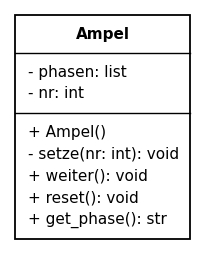



**Erwartete Ausgabe:**
```
rotgelb
grün
gelb
rot
rotgelb
rot
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Ampel:
    def __init__(self):
        self.__phasen = ['rot', 'rotgelb', 'grün', 'gelb']
        self.__nr = 0

    def __setze(self, nr):
        if nr < 0 or nr >= len(self.__phasen):
            raise ValueError('ungültige Phase')
        self.__nr = nr

    def weiter(self):
        self.__setze((self.__nr + 1) % len(self.__phasen))

    def reset(self):
        self.__setze(0)

    def get_phase(self):
        return self.__phasen[self.__nr]

a = Ampel()
for i in range(5):
    a.weiter()
    print(a.get_phase())
a.reset()
print(a.get_phase())
```

</details>

#### Aufgabe 8.2

Setze die Klasse um. Ein Parkhaus hat eine feste Zahl von Plätzen. `einfahren()` gibt `False` zurück, wenn es voll ist, `ausfahren()`, wenn es leer ist,
sonst `True`. `get_frei()` gibt die Zahl der freien Plätze zurück. Führe die Ereignisse in `ereignisse` aus (`'E'` einfahren, `'A'` ausfahren) und gib jeweils
das Ergebnis und die freien Plätze aus.

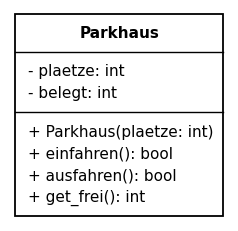



**Erwartete Ausgabe:**
```
E True 2
E True 1
E True 0
A True 1
E True 0
E False 0
A True 1
```

In [ ]:
ereignisse = 'EEEAEEA'
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
ereignisse = 'EEEAEEA'
class Parkhaus:
    def __init__(self, plaetze):
        self.__plaetze = plaetze
        self.__belegt = 0

    def einfahren(self):
        if self.__belegt == self.__plaetze:
            return False
        self.__belegt += 1
        return True

    def ausfahren(self):
        if self.__belegt == 0:
            return False
        self.__belegt -= 1
        return True

    def get_frei(self):
        return self.__plaetze - self.__belegt

p = Parkhaus(3)
for e in ereignisse:
    if e == 'E':
        ergebnis = p.einfahren()
    else:
        ergebnis = p.ausfahren()
    print(e, ergebnis, p.get_frei())
```

</details>

#### Aufgabe 8.3

Setze die Klasse um. `naechste()` gibt die nächste Vokabel als Paar zurück (am Ende wieder von vorne). `antworten(wort)` prüft die Antwort zur zuletzt
gezeigten Vokabel, zählt richtige Antworten und gibt `True`/`False` zurück. `get_quote()` gibt den Anteil richtiger Antworten in Prozent zurück (ganzzahlig, `//`).
Spiele vier Runden: zeige mit `naechste()` das deutsche Wort und beantworte mit den Antworten aus `antworten`.

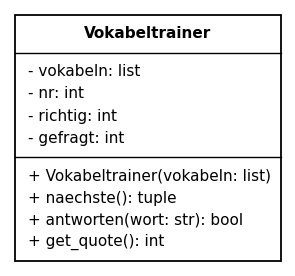



**Erwartete Ausgabe:**
```
Hund dog True
Katze cat True
Haus home False
Hund dog True
75
```

In [ ]:
vokabeln = [('Hund', 'dog'), ('Katze', 'cat'), ('Haus', 'house')]
antworten = ['dog', 'cat', 'home', 'dog']
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
vokabeln = [('Hund', 'dog'), ('Katze', 'cat'), ('Haus', 'house')]
antworten = ['dog', 'cat', 'home', 'dog']
class Vokabeltrainer:
    def __init__(self, vokabeln):
        self.__vokabeln = vokabeln
        self.__nr = -1
        self.__richtig = 0
        self.__gefragt = 0

    def naechste(self):
        self.__nr = (self.__nr + 1) % len(self.__vokabeln)
        return self.__vokabeln[self.__nr]

    def antworten(self, wort):
        self.__gefragt += 1
        if wort == self.__vokabeln[self.__nr][1]:
            self.__richtig += 1
            return True
        return False

    def get_quote(self):
        return self.__richtig * 100 // self.__gefragt

v = Vokabeltrainer(vokabeln)
for a in antworten:
    deutsch, englisch = v.naechste()
    print(deutsch, a, v.antworten(a))
print(v.get_quote())
```

</details>

#### Aufgabe 8.4

Schreibe eine Klasse `Konto` mit privatem Kontostand, einem privaten Klassenattribut für die nächste Kontonummer (beginnt bei 1000) und einer
Klassenmethode `get_anzahl()`, die zurückgibt, wie viele Konten es gibt. Jedes Konto bekommt eine Kontonummer (Getter `get_nr()`).
Die Methode `ueberweisen(ziel, betrag)` bucht nur, wenn genug Geld da ist, und gibt zurück, ob es geklappt hat.
Teste: Konto `a` mit 100, Konto `b` mit 0; überweise 70 von a nach b, dann 50 von a nach b. Gib Nummern, Stände und Anzahl aus.

**Erwartete Ausgabe:**
```
True
False
1000 30
1001 70
2
```

In [ ]:
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
class Konto:
    __naechste_nr = 1000

    def __init__(self, stand):
        self.__stand = stand
        self.__nr = Konto.__naechste_nr
        Konto.__naechste_nr += 1

    @classmethod
    def get_anzahl(cls):
        return cls.__naechste_nr - 1000

    def get_nr(self):
        return self.__nr

    def get_stand(self):
        return self.__stand

    def ueberweisen(self, ziel, betrag):
        if betrag > self.__stand:
            return False
        self.__stand -= betrag
        ziel.__stand += betrag
        return True

a = Konto(100)
b = Konto(0)
print(a.ueberweisen(b, 70))
print(a.ueberweisen(b, 50))
print(a.get_nr(), a.get_stand())
print(b.get_nr(), b.get_stand())
print(Konto.get_anzahl())
```

</details>

In der Aufgabe davor greift `ueberweisen()` auf `ziel.__stand` zu, das private Attribut eines **anderen** Objekts. Das ist erlaubt,
weil der Code in derselben Klasse steht: Privat heißt „nur innerhalb der Klasse“, nicht „nur für dasselbe Objekt“.

In [ ]:
class Punkt:
    def __init__(self, x):
        self.__x = x

    def gleich(self, other):
        return self.__x == other.__x

print(Punkt(3).gleich(Punkt(3)))

#### Aufgabe 8.5

Schreibe eine Klasse `Highscore` mit einer privaten Liste von Paaren `(name, punkte)`. `eintragen(name, punkte)` fügt ein Paar hinzu und behält nur
die besten drei (sortiert mit `sort(key=..., reverse=True)` und Slicing). `get_liste()` gibt eine **Kopie** zurück. `__str__` gibt die Liste in Zeilen
der Form `1. Mia 980` aus. Trage alle Ergebnisse aus `ergebnisse` ein und gib den Highscore aus.

**Erwartete Ausgabe:**
```
1. Ida 990
2. Mia 980
3. Cem 720
```

In [ ]:
ergebnisse = [('Ali', 500), ('Mia', 980), ('Cem', 720), ('Bea', 610), ('Ida', 990)]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
ergebnisse = [('Ali', 500), ('Mia', 980), ('Cem', 720), ('Bea', 610), ('Ida', 990)]
class Highscore:
    def __init__(self):
        self.__liste = []

    def eintragen(self, name, punkte):
        self.__liste.append((name, punkte))
        self.__liste.sort(key=lambda e: e[1], reverse=True)
        self.__liste = self.__liste[:3]

    def get_liste(self):
        return list(self.__liste)

    def __str__(self):
        zeilen = []
        for platz, (name, punkte) in enumerate(self.__liste, 1):
            zeilen.append(f'{platz}. {name} {punkte}')
        return '\n'.join(zeilen)

h = Highscore()
for name, punkte in ergebnisse:
    h.eintragen(name, punkte)
print(h)
```

</details>

#### Aufgabe 8.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
class Konto:
    __anzahl = 0

    def __init__(self, stand):
        self.__stand = stand
        Konto.__anzahl += 1

    def set_stand(self, stand):
        if stand >= 0:
            self.__stand = stand

    def get_stand(self):
        return self.__stand

    @classmethod
    def anzahl(cls):
        return cls.__anzahl

a = Konto(10)
b = a
b.set_stand(-5)
b.set_stand(20)
c = Konto(a.get_stand())
print(a.get_stand(), c.get_stand(), Konto.anzahl())